# 4. Annotate the page

Draw blue bubble IDs and red character IDs. Append a wrapped OCR legend beside the image so the original artwork stays visible. No model is needed.

Run cells top to bottom, then inspect the displayed output before continuing.


In [1]:
from pathlib import Path
import hashlib
import json
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# Works when the kernel starts in the project root or this stage folder.
ROOT = Path.cwd().resolve()
if not (ROOT / "models.json").exists():
    ROOT = ROOT.parent
if not (ROOT / "models.json").exists():
    raise FileNotFoundError("Start the kernel in 1pageTest or a stage folder.")
SEQUENCE_ID = "seq_71033fec4de494fc"
PAGE_NUMBER = 2
# Dataset page filenames are zero-padded: page 1 is 01.png.
PAGE = ROOT / "TaskData/development/images" / SEQUENCE_ID / f"{PAGE_NUMBER:02d}.png"
OUT = ROOT / "data/intermediate"
OUT.mkdir(parents=True, exist_ok=True)
MODELS = json.loads((ROOT / "models.json").read_text(encoding="utf-8"))
if not PAGE.is_file():
    raise FileNotFoundError(f"Put your manga page at {PAGE}, or edit PAGE.")
page = Image.open(PAGE).convert("RGB")
PAGE_INFO = {"name": PAGE.name, "sha256": hashlib.sha256(PAGE.read_bytes()).hexdigest(),
             "width": page.width, "height": page.height}

def save_stage(name, records):
    path = OUT / name
    path.write_text(json.dumps({"page": PAGE_INFO, "records": records},
                               ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Saved {path}")

def load_stage(name):
    path = OUT / name
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}; run the preceding stage first.")
    payload = json.loads(path.read_text(encoding="utf-8"))
    if payload["page"] != PAGE_INFO:
        raise ValueError(f"{name} belongs to a different page. Rerun the earlier stages.")
    return payload["records"]


Saved C:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\data\intermediate\annotation.json


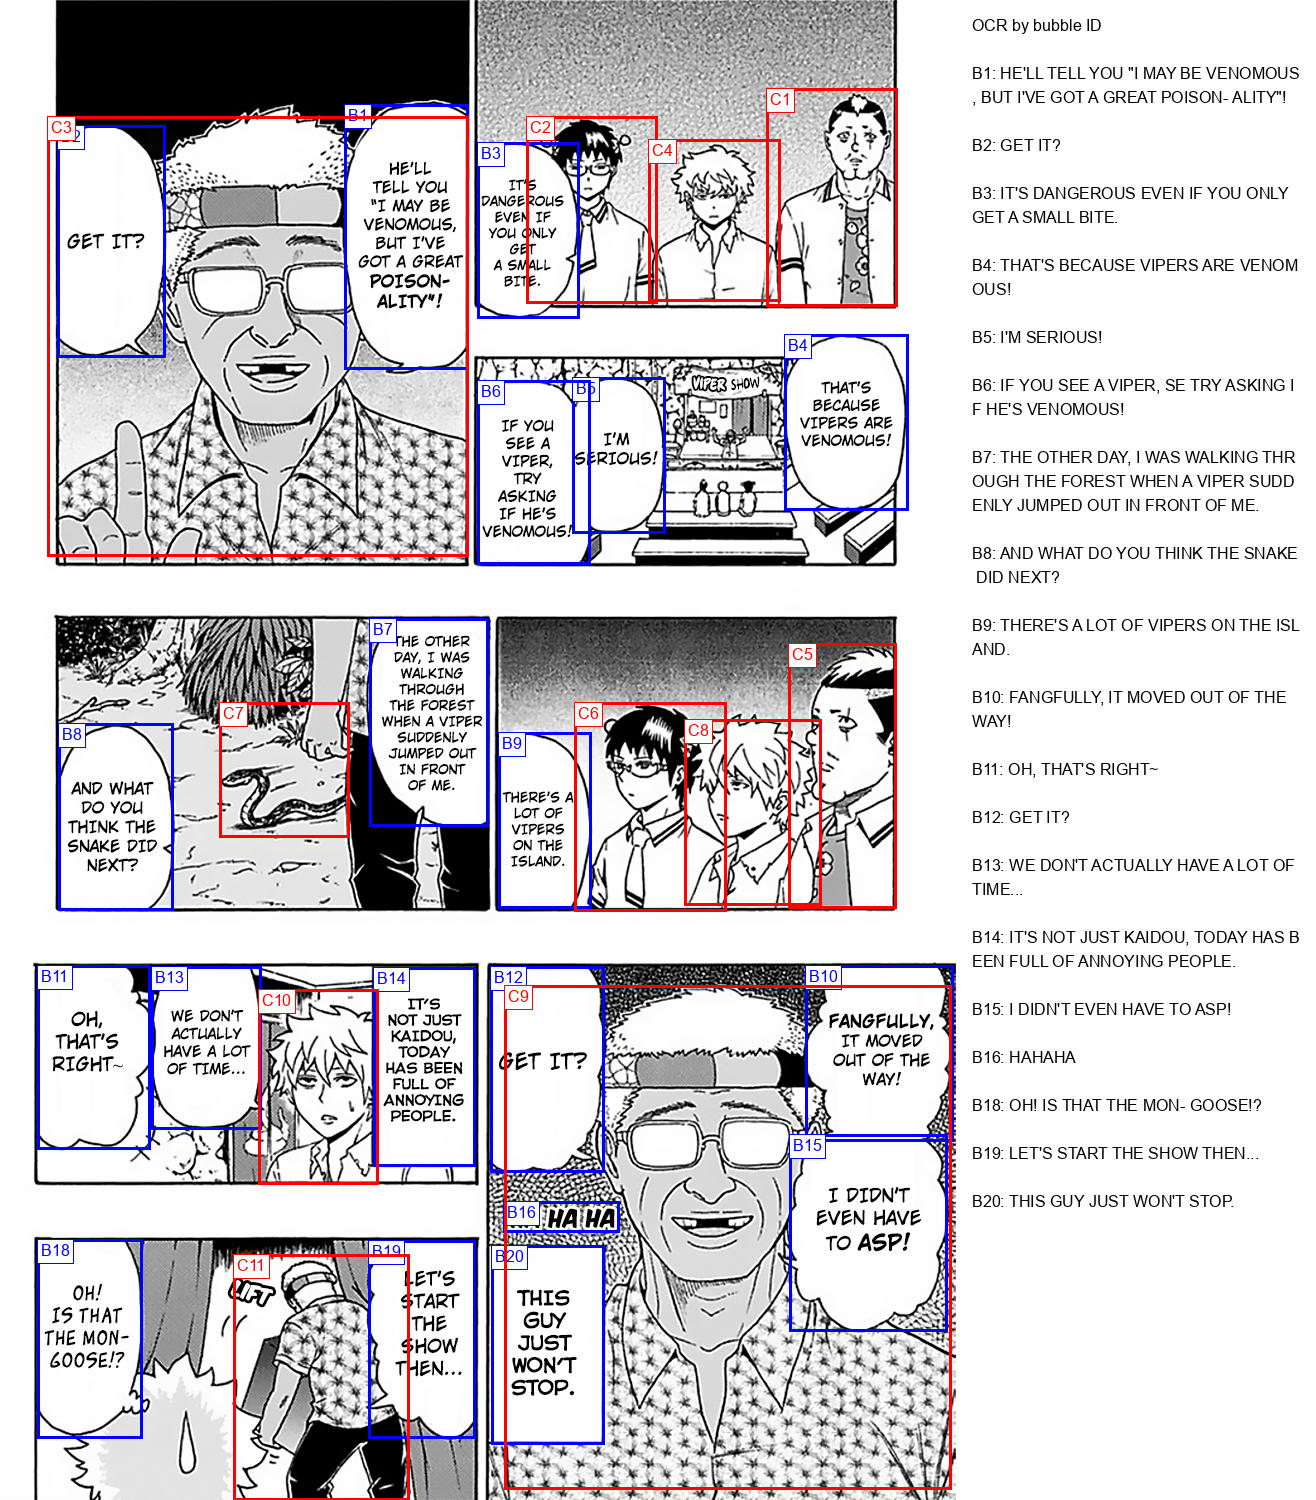

In [2]:
import textwrap

bubbles = load_stage("bubbles_clean.json")
characters = load_stage("characters.json")
ocr_results = load_stage("ocr_clean.json")
if {b["bubble_id"] for b in bubbles} != {r["bubble_id"] for r in ocr_results}:
    raise ValueError("Bubble IDs and OCR IDs differ; rerun OCR.")
font_size = max(16, page.width // 60)
font_path = Path("C:/Windows/Fonts/arial.ttf")
font = ImageFont.truetype(str(font_path), font_size) if font_path.exists() else ImageFont.load_default(size=font_size)
legend_width = max(360, page.width // 3)
line_height = font_size + 8
legend_lines = ["OCR by bubble ID", ""]
for record in ocr_results:
    text = f"{record['bubble_id']}: {record['text'] or '[no text recognized]'}"
    # Wrap by measured pixel width, including long unbroken strings.
    line = ""
    for char in text:
        if line and font.getlength(line + char) > legend_width - 32:
            legend_lines.append(line)
            line = ""
        line += char
    legend_lines.extend([line, ""])
annotated = Image.new("RGB", (page.width + legend_width, max(page.height, (len(legend_lines) + 2) * line_height)), "white")
annotated.paste(page, (0, 0))
draw = ImageDraw.Draw(annotated)

def mark(box, label, color):
    x1, y1, x2, y2 = box
    draw.rectangle((x1, y1, x2, y2), outline=color, width=3)
    label_width = int(font.getlength(label)) + 8
    lx = max(0, min(x1, page.width - label_width))
    ly = max(0, min(y1, page.height - line_height))
    draw.rectangle((lx, ly, lx + label_width, ly + line_height), fill="white", outline=color)
    draw.text((lx + 4, ly + 2), label, font=font, fill=color)

for bubble in bubbles:
    mark(bubble["box"], bubble["bubble_id"], "blue")
for character in characters:
    mark(character["box"], character["character_id"], "red")
for i, line in enumerate(legend_lines):
    draw.text((page.width + 16, 16 + i * line_height), line, fill="black", font=font)
ANNOTATED = OUT / "annotated_page.png"
annotated.save(ANNOTATED)
save_stage("annotation.json", {"image": ANNOTATED.name,
    "image_sha256": hashlib.sha256(ANNOTATED.read_bytes()).hexdigest(),
    "inputs_sha256": {name: hashlib.sha256((OUT / name).read_bytes()).hexdigest()
                      for name in ("bubbles_clean.json", "characters.json", "ocr_clean.json")}})
display(annotated)
